# Task 1 · Part 2 — Answering the Business Questions
This notebook continues from `01_cleaning_and_features.ipynb`. It starts from the cleaned table (`outputs/retail_clean.csv`: one row per transaction, with `Revenue`, `Profit`, `Age` etc. already derived) and answers the six business questions one by one. Each section has the numbers, a chart, and a plain-language takeaway.

**Conventions:** `Revenue` = what customers pay after discount; `Profit` = Revenue − cost; `Margin` = Profit ÷ Revenue (computed on totals, not averaged per transaction). The dataset has no currency, so values are in currency units.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from pathlib import Path
from scipy import stats

OUT = Path("../outputs"); FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

df = pd.read_csv(OUT / "retail_clean.csv", parse_dates=["Date", "BirthDate", "JoinDate"])

# --- chart style: one blue for magnitude, orange only for emphasis, quiet grid ---
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"   # categorical slots 1-3 (validated colour-blind safe)
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "font.size": 10, "legend.frameon": False,
})

def money(x, pos=None):
    return f"{x/1e6:.1f}M" if abs(x) >= 1e6 else (f"{x/1e3:.0f}k" if abs(x) >= 1e3 else f"{x:.0f}")
MONEY = FuncFormatter(money)
def money2(x):
    return f"{x/1e6:.2f}M" if abs(x) >= 1e6 else money(x)

def style(ax, grid="y"):
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    ax.grid(axis=grid, color=GRID, lw=0.8); ax.set_axisbelow(True)
    ax.tick_params(length=0)

def save(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")

print("Rows:", len(df), "| period:", df.Date.min().date(), "to", df.Date.max().date())
print(f"Revenue {df.Revenue.sum():,.0f} | Profit {df.Profit.sum():,.0f} | Margin {df.Profit.sum()/df.Revenue.sum():.1%}")

Rows: 5000 | period: 2023-09-10 to 2025-09-09
Revenue 14,301,903 | Profit 3,826,315 | Margin 26.8%


---
## Initial inspection and descriptive statistics
Before answering the business questions, a quick look at the cleaned table: its shape, column types, missing values and the basic statistics of every numeric column.

In [2]:
print("Shape (rows, columns):", df.shape)
info = pd.DataFrame({"dtype": df.dtypes.astype(str), "non-null": df.notna().sum(), "nulls": df.isna().sum(), "unique": df.nunique()})
info

Shape (rows, columns): (5000, 36)


,dtype,non-null,nulls,unique
TransactionID,str,5000,0,5000
Date,datetime64[us],5000,0,729
CustomerID,str,5000,0,200
ProductID,str,5000,0,50
StoreID,str,5000,0,5
Quantity,int64,5000,0,5
Discount,float64,5000,0,4
PaymentMethod,str,5000,0,4
ProductName,str,5000,0,50
Category,str,5000,0,3


In [3]:
num_cols = ["Quantity", "Discount", "UnitPrice", "CostPrice", "GrossSales", "Revenue", "Profit", "ProfitMargin", "Age"]
desc = df[num_cols].agg(["mean", "median", "std", "min", "max"]).T
desc["mode"] = df[num_cols].mode().iloc[0]
desc[["mean", "median", "mode", "std", "min", "max"]]

,mean,median,mode,std,min,max
Quantity,2.99,3.00,2.00,1.41,1.00,5.00
Discount,0.08,0.10,0.15,0.06,0.00,0.15
UnitPrice,"1,036.61","1,193.09","1,134.80",589.32,25.57,"1,952.65"
CostPrice,702.00,794.80,675.10,426.69,15.28,"1,451.27"
GrossSales,"3,095.03","2,386.18","1,879.08","2,435.65",25.57,"9,763.25"
Revenue,"2,860.38","2,156.12","4,267.91","2,265.96",21.73,"9,763.25"
Profit,765.26,555.11,297.77,711.18,2.68,"4,372.60"
ProfitMargin,0.28,0.27,0.25,0.11,0.06,0.50
Age,43.41,44.00,63.00,15.42,16.00,70.00


**Observations.**
- The table has 5,000 rows and no missing values, so no imputation is needed.
- **Order sizes:** the typical order is 3 units (mean 2.99, median 3, mode 2) of between 1 and 5, so orders are small.
- **Revenue is right-skewed:** mean revenue per order (2,860) is well above the median (2,156), and its standard deviation (2,266) is nearly as large as the mean. A minority of large orders pulls the average up, so the median is the better "typical order".
- **Discounts:** the average discount is 7.6%, with the most common value being 15% (mode), and it ranges from 0% to 15%.
- **Margin:** profit margin averages 27.8% per order (median 26.5%), ranging from 6% to 50%.
- The mode is only really meaningful for the discrete columns (Quantity, Discount); for continuous columns such as Revenue it just picks one repeated value.

---
## Q1. Which products and categories drive the most sales and profit?
I first compare the three categories, then drill into sub-categories and individual products. Sales (revenue) and profit are shown separately, because a product can sell a lot yet earn little.

In [4]:
def summarise(g):
    out = g.agg(Revenue=("Revenue", "sum"), Profit=("Profit", "sum"),
                Units=("Quantity", "sum"), Orders=("TransactionID", "count"))
    out["Margin"] = out.Profit / out.Revenue
    out["RevShare"] = out.Revenue / out.Revenue.sum()
    return out

cat = summarise(df.groupby("Category")).sort_values("Revenue", ascending=False)
cat

,Revenue,Profit,Units,Orders,Margin,RevShare
Category,,,,,,
Electronics,"6,316,917.32","1,632,228.95",5431,1801,0.26,0.44
Fashion,"6,232,279.75","1,660,525.19",7015,2365,0.27,0.44
Groceries,"1,752,706.09","533,560.53",2503,834,0.30,0.12


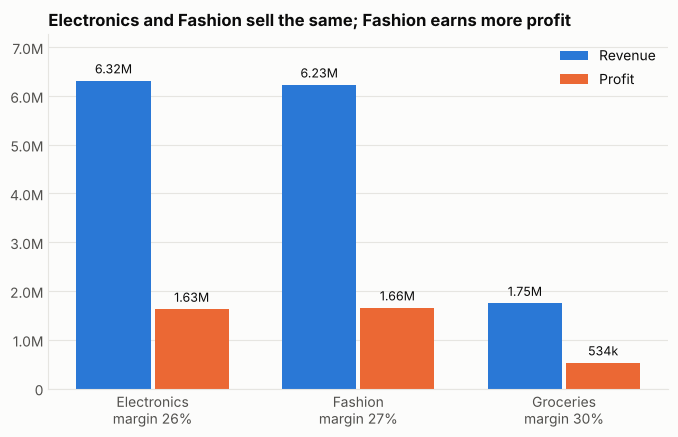

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.6))
x = np.arange(len(cat)); w = 0.36
b1 = ax.bar(x - 0.19, cat.Revenue, w, color=BLUE, label="Revenue")
b2 = ax.bar(x + 0.19, cat.Profit, w, color=ORANGE, label="Profit")
ax.bar_label(b1, labels=[money2(v) for v in cat.Revenue], padding=3, fontsize=9)
ax.bar_label(b2, labels=[money2(v) for v in cat.Profit], padding=3, fontsize=9)
ax.set_xticks(x, [f"{c}\nmargin {m:.0%}" for c, m in zip(cat.index, cat.Margin)])
ax.yaxis.set_major_formatter(MONEY); ax.set_ylim(0, cat.Revenue.max() * 1.15)
ax.set_title("Electronics and Fashion sell the same; Fashion earns more profit")
ax.legend(loc="upper right"); style(ax); save(fig, "q1_category_revenue_profit.png"); plt.show()

**Takeaway.** Electronics (6.32M) and Fashion (6.23M) each bring in about 44% of revenue, but **Fashion earns the most profit (1.66M)** because its margin is a little higher (26.6% vs 25.8%). Groceries is small (12% of revenue) but has the **best margin (30.4%)**.

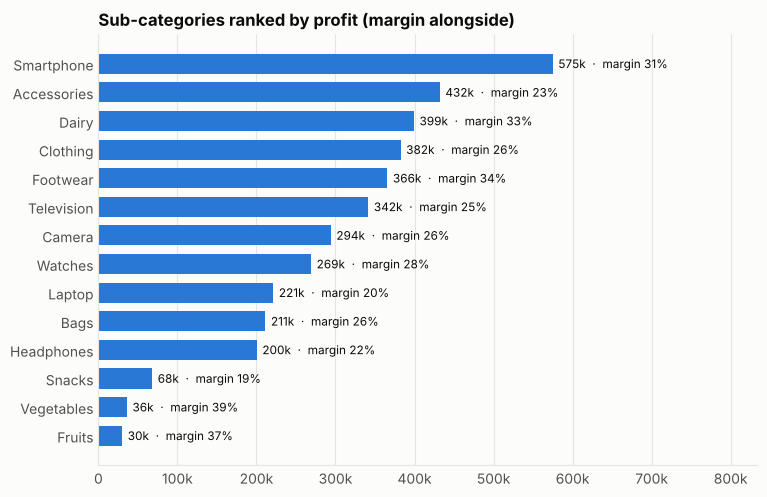

,Category,SubCategory,Revenue,Profit,Units,Orders,Margin,RevShare
0,Electronics,Smartphone,"1,853,361.12","574,825.76",1746,597,0.31,0.13
1,Fashion,Accessories,"1,915,156.61","431,990.92",1612,556,0.23,0.13
2,Groceries,Dairy,"1,221,534.44","399,292.01",950,322,0.33,0.09
3,Fashion,Clothing,"1,459,663.27","382,461.45",1515,512,0.26,0.10
4,Fashion,Footwear,"1,090,244.69","365,644.14",1489,497,0.34,0.08
5,Electronics,Television,"1,341,301.74","341,582.40",995,321,0.25,0.09
6,Electronics,Camera,"1,130,805.65","294,062.79",845,282,0.26,0.08
7,Fashion,Watches,"949,474.32","269,117.91",1464,503,0.28,0.07
8,Electronics,Laptop,"1,085,241.80","221,329.50",951,306,0.20,0.08
9,Fashion,Bags,"817,740.85","211,310.76",935,297,0.26,0.06


In [6]:
sub = summarise(df.groupby(["Category", "SubCategory"])).reset_index().sort_values("Profit")
fig, ax = plt.subplots(figsize=(8.5, 5.6))
bars = ax.barh(sub.SubCategory, sub.Profit, color=BLUE, height=0.7)
ax.bar_label(bars, labels=[f"{money(p)}  ·  margin {m:.0%}" for p, m in zip(sub.Profit, sub.Margin)], padding=4, fontsize=8.5)
ax.xaxis.set_major_formatter(MONEY); ax.set_xlim(0, sub.Profit.max() * 1.45)
ax.set_title("Sub-categories ranked by profit (margin alongside)")
style(ax, grid="x"); save(fig, "q1_subcategory_profit.png"); plt.show()
sub.sort_values("Profit", ascending=False).reset_index(drop=True)

**Takeaway.** Smartphones (575k) are the most profitable sub-category, followed by Accessories and Dairy. **Accessories is the biggest seller by revenue (1.92M) but its margin is only 23%**, and Laptops (20%) and Snacks (19%) are the weakest. Footwear (34%) and Dairy (33%) earn the best returns among the larger sub-categories.

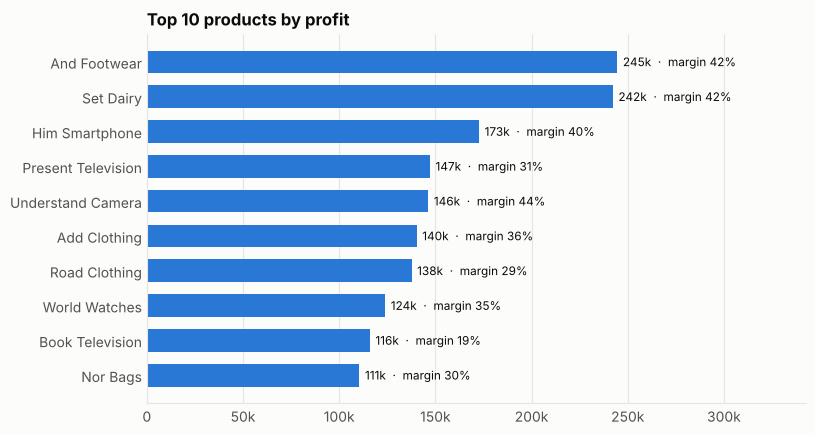

Top 10 products' share of total revenue: 36.3%


,ProductName,Category,Revenue,Profit,Margin
6,Book Television,Electronics,"605,028.60","115,950.61",0.19
2,And Footwear,Fashion,"585,613.02","244,603.26",0.42
40,Set Dairy,Groceries,"573,777.08","242,272.28",0.42
45,Traditional Laptop,Electronics,"521,031.01","94,196.85",0.18
4,Beat Accessories,Fashion,"498,224.74","100,808.89",0.20


In [7]:
prod = df.groupby(["ProductName", "Category"]).agg(Revenue=("Revenue", "sum"), Profit=("Profit", "sum"),
                                                   Units=("Quantity", "sum")).reset_index()
prod["Margin"] = prod.Profit / prod.Revenue

top = prod.nlargest(10, "Profit").sort_values("Profit")
fig, ax = plt.subplots(figsize=(8.5, 4.8))
bars = ax.barh(top.ProductName, top.Profit, color=BLUE, height=0.65)
ax.bar_label(bars, labels=[f"{money(p)}  ·  margin {m:.0%}" for p, m in zip(top.Profit, top.Margin)], padding=4, fontsize=8.5)
ax.xaxis.set_major_formatter(MONEY); ax.set_xlim(0, top.Profit.max() * 1.4)
ax.set_title("Top 10 products by profit"); style(ax, grid="x"); save(fig, "q1_top_products_profit.png"); plt.show()

print("Top 10 products' share of total revenue:", f"{prod.nlargest(10, 'Revenue').Revenue.sum() / prod.Revenue.sum():.1%}")
prod.nlargest(5, "Revenue")[["ProductName", "Category", "Revenue", "Profit", "Margin"]]

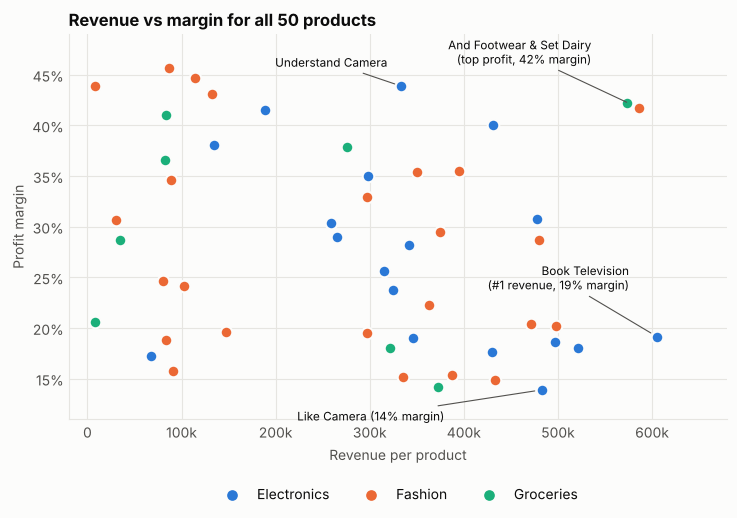

In [8]:
colors = {"Electronics": BLUE, "Fashion": ORANGE, "Groceries": AQUA}
fig, ax = plt.subplots(figsize=(8.5, 5))
for c, g in prod.groupby("Category"):
    ax.scatter(g.Revenue, g.Margin, s=70, color=colors[c], edgecolor=SURF, linewidth=1.5, label=c, zorder=3)
labels = [  # (label text, product(s) it points to, text offset in points, alignment)
    ("Book Television\n(#1 revenue, 19% margin)", ["Book Television"], (-20, 34), "right"),
    ("And Footwear & Set Dairy\n(top profit, 42% margin)", ["And Footwear", "Set Dairy"], (-30, 30), "right"),
    ("Like Camera (14% margin)", ["Like Camera"], (-70, -22), "right"),
    ("Understand Camera", ["Understand Camera"], (-10, 14), "right"),
]
for text, names, off, ha in labels:
    pts = prod[prod.ProductName.isin(names)]
    ax.annotate(text, (pts.Revenue.mean(), pts.Margin.mean()), xytext=off, textcoords="offset points", fontsize=8.5,
                color=INK, ha=ha, arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8, shrinkA=2, shrinkB=5))
ax.xaxis.set_major_formatter(MONEY); ax.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:.0%}"))
ax.set_xlabel("Revenue per product"); ax.set_ylabel("Profit margin"); ax.set_ylim(0.11, 0.49); ax.set_xlim(-20000, 680000)
ax.set_title("Revenue vs margin for all 50 products")
ax.legend(title=None, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, markerscale=1.1)
style(ax, grid="both"); save(fig, "q1_product_revenue_vs_margin.png"); plt.show()

**Takeaway.** Sales are spread widely: the top 10 products make up only 36% of revenue. The #1 seller by revenue, *Book Television* (605k), has a low 19% margin, whereas *And Footwear* and *Set Dairy* earn 42% margins and take the top two profit spots (245k and 242k). Products such as *Like Camera* sell well (482k) but keep only 14%. **Promoting high-margin, high-volume items would lift profit more than chasing revenue alone.**

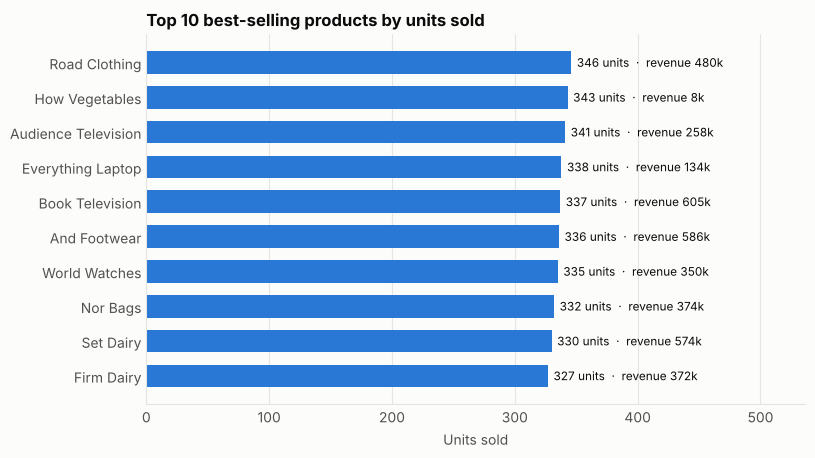

,ProductName,Units,Revenue,Profit,Margin
0,Road Clothing,346,"479,596.90","137,641.64",0.29
1,How Vegetables,343,"8,233.54","1,699.39",0.21
2,Audience Television,341,"258,359.72","78,441.30",0.30
3,Everything Laptop,338,"134,386.30","51,214.64",0.38
4,Book Television,337,"605,028.60","115,950.61",0.19
5,And Footwear,336,"585,613.02","244,603.26",0.42
6,World Watches,335,"350,085.80","123,927.30",0.35
7,Nor Bags,332,"374,395.61","110,522.01",0.30
8,Set Dairy,330,"573,777.08","242,272.28",0.42
9,Firm Dairy,327,"372,283.25","52,774.82",0.14


In [9]:
best = df.groupby("ProductName").agg(Units=("Quantity", "sum"), Revenue=("Revenue", "sum"), Profit=("Profit", "sum")).nlargest(10, "Units").reset_index()
best["Margin"] = best.Profit / best.Revenue
b10 = best.sort_values("Units")
fig, ax = plt.subplots(figsize=(8.5, 4.8))
bars = ax.barh(b10.ProductName, b10.Units, color=BLUE, height=0.65)
ax.bar_label(bars, labels=[f"{u:,.0f} units  ·  revenue {money(r)}" for u, r in zip(b10.Units, b10.Revenue)], padding=4, fontsize=8.5)
ax.set_xlim(0, b10.Units.max() * 1.55); ax.set_xlabel("Units sold")
ax.set_title("Top 10 best-selling products by units sold"); style(ax, grid="x"); save(fig, "q1_top10_units.png"); plt.show()
best

**Observations.** The best-selling products by units sold (327–346 units each) are almost tied, so no single product dominates. **Units and money tell different stories:** *How Vegetables* is the #2 seller by units (343) but earns only 8k in revenue because it costs very little, while *Book Television* sells a similar number of units (337) and earns 605k. Ranking by units alone would hide where the money is, which is why Q1 is judged on revenue and profit.

---
## Q2. What is the trend of sales over time?
**Watch the edges of the data.** Transactions run from **10 Sep 2023 to 9 Sep 2025**, so 2023 (113 days) and 2025 (252 days) are partial years, and two quarters/months are partial too. Comparing raw yearly totals would be misleading, so I compare like-for-like periods and flag partial periods.

In [10]:
yr = df.groupby("Year").agg(Revenue=("Revenue", "sum"), Profit=("Profit", "sum"), Orders=("TransactionID", "count"),
                            First=("Date", "min"), Last=("Date", "max"))
yr["Days"] = (yr.Last - yr.First).dt.days + 1
yr["RevenuePerDay"] = yr.Revenue / yr.Days
yr["Margin"] = yr.Profit / yr.Revenue
display(yr[["First", "Last", "Days", "Revenue", "RevenuePerDay", "Profit", "Margin"]])

jan_aug = df[df.Date.dt.month <= 8].groupby("Year").Revenue.sum()
print(f"Like-for-like Jan-Aug: 2024 = {jan_aug[2024]:,.0f} | 2025 = {jan_aug[2025]:,.0f} | growth = {jan_aug[2025]/jan_aug[2024]-1:+.1%}")

,First,Last,Days,Revenue,RevenuePerDay,Profit,Margin
Year,,,,,,,
2023,2023-09-10,2023-12-31,113,"2,179,931.91","19,291.43","593,917.12",0.27
2024,2024-01-01,2024-12-31,366,"7,026,767.23","19,198.82","1,868,374.79",0.27
2025,2025-01-01,2025-09-09,252,"5,095,204.00","20,219.06","1,364,022.75",0.27


Like-for-like Jan-Aug: 2024 = 4,544,743 | 2025 = 4,949,244 | growth = +8.9%


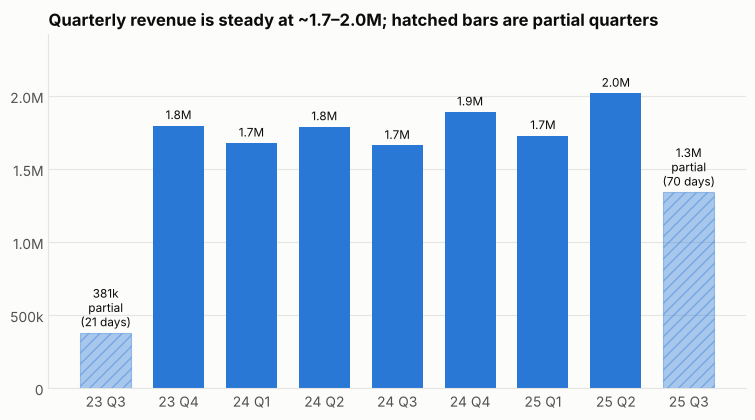

In [11]:
q = df.groupby("Quarter").agg(Revenue=("Revenue", "sum"), Days=("Date", "nunique"))
partial = {"2023Q3": "partial\n(21 days)", "2025Q3": "partial\n(70 days)"}
fig, ax = plt.subplots(figsize=(9, 4.6))
for i, (qq, row) in enumerate(q.iterrows()):
    is_part = qq in partial
    bar = ax.bar(i, row.Revenue, 0.7, color=BLUE, alpha=0.4 if is_part else 1, hatch="///" if is_part else None,
                 edgecolor=SURF if not is_part else BLUE, linewidth=0 if not is_part else 0.8)
    ax.text(i, row.Revenue + 25000, money(row.Revenue) + (f"\n{partial[qq]}" if is_part else ""),
            ha="center", va="bottom", fontsize=8.5, color=INK)
ax.set_xticks(range(len(q)), [s[2:4] + " " + s[4:] for s in q.index])
ax.yaxis.set_major_formatter(MONEY); ax.set_ylim(0, q.Revenue.max() * 1.2)
ax.set_title("Quarterly revenue is steady at ~1.7–2.0M; hatched bars are partial quarters")
style(ax); save(fig, "q2_quarterly_revenue.png"); plt.show()

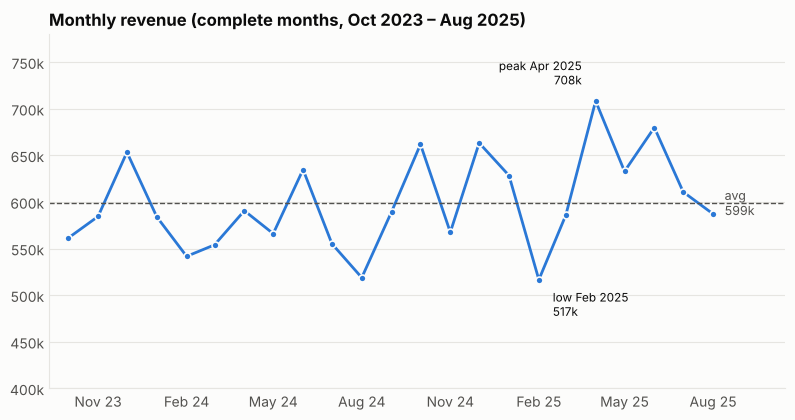

Monthly revenue: min 516,524 | max 708,233 | mean 598,911


In [12]:
m = df.groupby("YearMonth").Revenue.sum()
m = m.loc["2023-10":"2025-08"]                       # complete months only
m.index = pd.to_datetime(m.index)
fig, ax = plt.subplots(figsize=(9.5, 4.6))
ax.plot(m.index, m.values, color=BLUE, lw=2, marker="o", markersize=5, markeredgecolor=SURF, markeredgewidth=1.2)
ax.axhline(m.mean(), color=INK2, lw=1, ls="--")
ax.set_xlim(m.index[0] - pd.Timedelta(days=20), m.index[-1] + pd.Timedelta(days=75))
ax.text(m.index[-1] + pd.Timedelta(days=12), m.mean(), f"avg\n{money(m.mean())}", color=INK2, fontsize=9, va="center")
hi, lo = m.idxmax(), m.idxmin()
ax.annotate(f"peak {hi:%b %Y}\n{money(m[hi])}", (hi, m[hi]), xytext=(-10, 12), textcoords="offset points", ha="right", fontsize=8.5)
ax.annotate(f"low {lo:%b %Y}\n{money(m[lo])}", (lo, m[lo]), xytext=(10, -26), textcoords="offset points", fontsize=8.5)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y")); ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.yaxis.set_major_formatter(MONEY); ax.set_ylim(400000, 780000)
ax.set_title("Monthly revenue (complete months, Oct 2023 – Aug 2025)")
style(ax); save(fig, "q2_monthly_revenue.png"); plt.show()
print("Monthly revenue: min", f"{m.min():,.0f}", "| max", f"{m.max():,.0f}", "| mean", f"{m.mean():,.0f}")

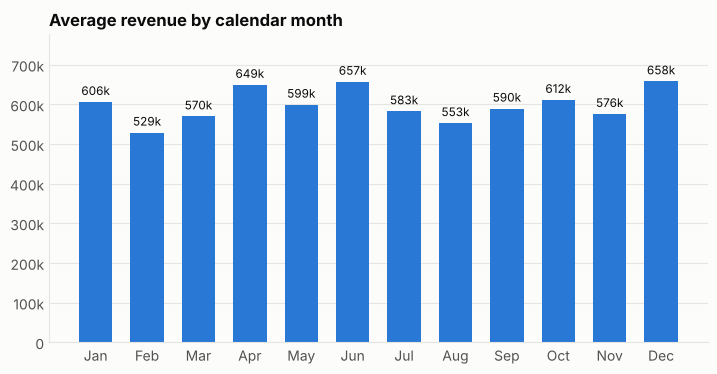

In [13]:
# Is there a seasonal pattern? Average revenue per calendar month, complete months only
mm = df.groupby("YearMonth").Revenue.sum().loc["2023-10":"2025-08"]
seasonal = mm.groupby(pd.to_datetime(mm.index).month).mean()
fig, ax = plt.subplots(figsize=(8.5, 4))
names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
bars = ax.bar([names[i - 1] for i in seasonal.index], seasonal.values, color=BLUE, width=0.65)
ax.bar_label(bars, labels=[money(v) for v in seasonal.values], padding=3, fontsize=8.5)
ax.yaxis.set_major_formatter(MONEY); ax.set_ylim(0, seasonal.max() * 1.18)
ax.set_title("Average revenue by calendar month"); style(ax); save(fig, "q2_seasonality.png"); plt.show()

**Takeaway.**
- **Sales grew steadily.** The only full calendar year is 2024 (7.03M). Comparing like with like, **Jan–Aug 2025 is +8.9% above Jan–Aug 2024**.
- Monthly revenue moves in a narrow band (517k–708k, average 599k). **April 2025 is the peak (708k)** and the 2025 Q2 quarter is the best (2.02M).
- **Seasonality is weak.** June and December are slightly higher and February slightly lower (it is also the shortest month), but there is no strong peak season, so promotions are not needed to rescue a slow period.
- Margin barely changes over time (26–28% every quarter), so growth is coming from volume, not pricing.

---
## Q3. Which stores or regions perform best?
There are 5 stores in 4 regions. **East has two stores** (Peckmouth and Johnmouth), so I compare regions in total *and* per store, to keep the comparison fair.

In [14]:
reg = summarise(df.groupby("Region")).sort_values("Revenue", ascending=False)
reg["Stores"] = df.groupby("Region").StoreID.nunique()
reg["RevenuePerStore"] = reg.Revenue / reg.Stores
sto = summarise(df.groupby(["StoreName", "Region"])).reset_index().sort_values("Revenue", ascending=False)
display(reg[["Stores", "Revenue", "RevenuePerStore", "Profit", "Margin"]])
display(sto[["StoreName", "Region", "Revenue", "Profit", "Margin", "Orders"]])

,Stores,Revenue,RevenuePerStore,Profit,Margin
Region,,,,,
East,2,"5,600,680.41","2,800,340.21","1,498,458.92",0.27
West,1,"2,920,406.93","2,920,406.93","804,011.47",0.28
North,1,"2,900,701.08","2,900,701.08","769,983.35",0.27
South,1,"2,880,114.73","2,880,114.73","753,860.93",0.26


,StoreName,Region,Revenue,Profit,Margin,Orders
3,MegaMart New Michele,West,"2,920,406.93","804,011.47",0.28,1013
0,MegaMart Brianahaven,North,"2,900,701.08","769,983.35",0.27,1011
1,MegaMart Jimenezborough,South,"2,880,114.73","753,860.93",0.26,1014
2,MegaMart Johnmouth,East,"2,847,047.80","772,924.95",0.27,953
4,MegaMart Peckmouth,East,"2,753,632.61","725,533.97",0.26,1009


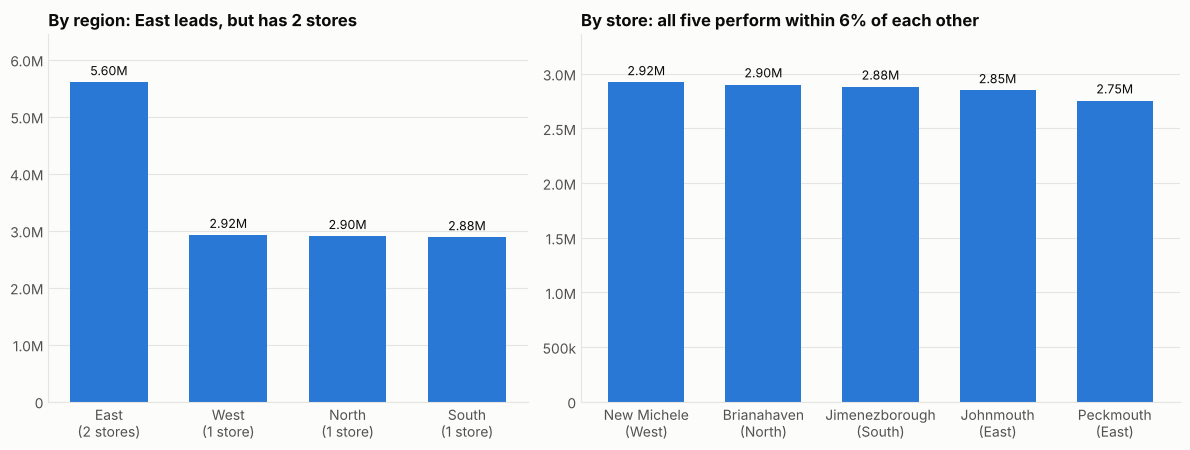

Best vs worst store gap: 6.1%


In [15]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [4, 5]})
b = a1.bar([f"{r}\n({int(s)} store{'s' if s > 1 else ''})" for r, s in zip(reg.index, reg.Stores)], reg.Revenue, color=BLUE, width=0.65)
a1.bar_label(b, labels=[money2(v) for v in reg.Revenue], padding=3, fontsize=9)
a1.yaxis.set_major_formatter(MONEY); a1.set_ylim(0, reg.Revenue.max() * 1.15)
a1.set_title("By region: East leads, but has 2 stores"); style(a1)

short = sto.StoreName.str.replace("MegaMart ", "")
b = a2.bar([f"{n}\n({r})" for n, r in zip(short, sto.Region)], sto.Revenue, color=BLUE, width=0.65)
a2.bar_label(b, labels=[money2(v) for v in sto.Revenue], padding=3, fontsize=9)
a2.yaxis.set_major_formatter(MONEY); a2.set_ylim(0, sto.Revenue.max() * 1.15)
a2.set_title("By store: all five perform within 6% of each other"); style(a2)
fig.tight_layout(); save(fig, "q3_region_store_revenue.png"); plt.show()
print(f"Best vs worst store gap: {sto.Revenue.max() / sto.Revenue.min() - 1:.1%}")

**Takeaway.** East looks like the winner (5.60M, 39% of revenue), but **only because it has two stores**. Per store, East earns 2.80M, which is in line with West, North and South (2.88–2.92M). Across the five stores, the best (**New Michele, West: 2.92M**) is just **6% above the weakest (Peckmouth, East: 2.75M)**. Margins are also the same everywhere (26–28%). Performance is consistent across the chain; no store or region is a standout or a problem.

---
## Q4. How do customer demographics (age, gender, city) influence sales?
Age changes over the two-year window (34 customers cross an age band), so for customer-level comparisons I use each customer's **age on the last date in the data** (9 Sep 2025). This puts every customer in exactly one group.

In [16]:
end = df.Date.max()
df["AgeNow"] = ((end - df.BirthDate).dt.days // 365.25).astype(int)
df["AgeBand"] = pd.cut(df.AgeNow, [0, 24, 34, 44, 54, 64, 120], labels=["<25", "25-34", "35-44", "45-54", "55-64", "65+"])

def by_group(col):
    g = df.groupby(col, observed=True)
    out = pd.DataFrame({"Customers": g.CustomerID.nunique(), "Revenue": g.Revenue.sum(), "Profit": g.Profit.sum(),
                        "Orders": g.TransactionID.count(), "AOV": g.Revenue.mean()})
    out["RevenuePerCustomer"] = out.Revenue / out.Customers
    out["OrdersPerCustomer"] = out.Orders / out.Customers
    return out

gender, age = by_group("Gender"), by_group("AgeBand")
display(gender); display(age)

,Customers,Revenue,Profit,Orders,AOV,RevenuePerCustomer,OrdersPerCustomer
Gender,,,,,,,
F,87,"6,231,304.70","1,652,497.03",2190,"2,845.34","71,624.19",25.17
M,113,"8,070,598.45","2,173,817.63",2810,"2,872.10","71,421.23",24.87


,Customers,Revenue,Profit,Orders,AOV,RevenuePerCustomer,OrdersPerCustomer
AgeBand,,,,,,,
<25,28,"1,962,820.98","515,995.20",676,"2,903.58","70,100.75",24.14
25-34,35,"2,528,329.47","687,520.85",891,"2,837.63","72,237.98",25.46
35-44,34,"2,485,616.81","658,347.82",879,"2,827.78","73,106.38",25.85
45-54,39,"2,761,496.01","757,261.95",943,"2,928.42","70,807.59",24.18
55-64,43,"3,171,986.63","847,452.44",1112,"2,852.51","73,767.13",25.86
65+,21,"1,391,653.24","359,736.40",499,"2,788.88","66,269.20",23.76


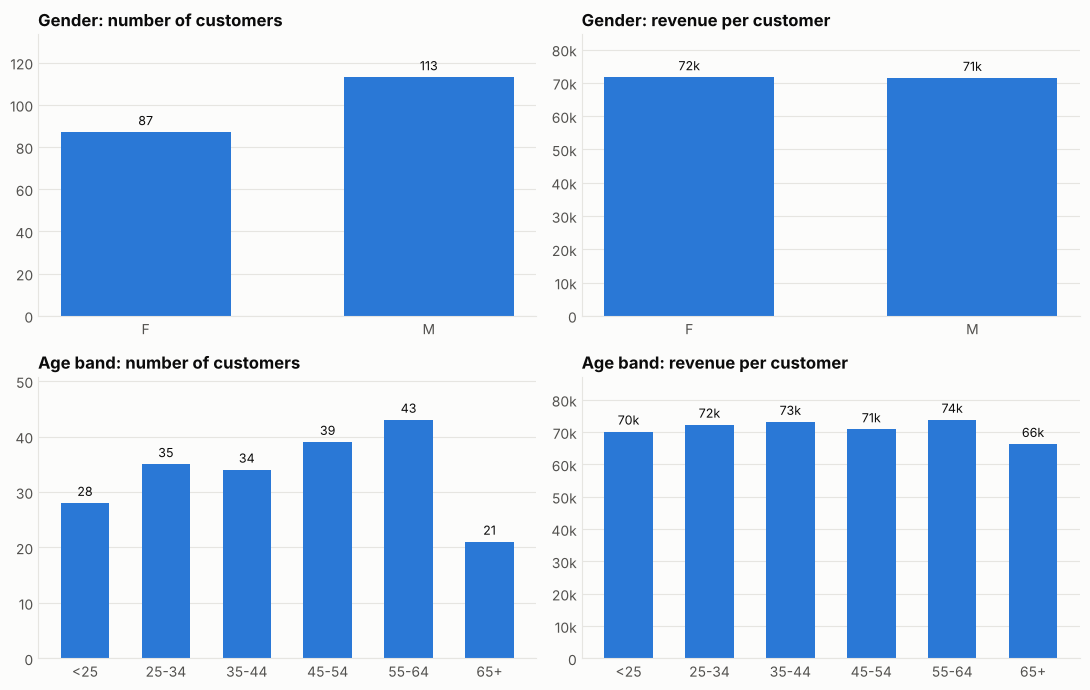

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
def panel(ax, series, title, fmt, ylim=None):
    b = ax.bar(series.index.astype(str), series.values, color=BLUE, width=0.6)
    ax.bar_label(b, labels=[fmt(v) for v in series.values], padding=3, fontsize=9)
    ax.set_title(title); style(ax)
    ax.set_ylim(0, series.max() * 1.18)
panel(axes[0, 0], gender.Customers, "Gender: number of customers", lambda v: f"{v:.0f}")
panel(axes[0, 1], gender.RevenuePerCustomer, "Gender: revenue per customer", money)
panel(axes[1, 0], age.Customers, "Age band: number of customers", lambda v: f"{v:.0f}")
panel(axes[1, 1], age.RevenuePerCustomer, "Age band: revenue per customer", money)
for ax in (axes[0, 1], axes[1, 1]): ax.yaxis.set_major_formatter(MONEY)
fig.tight_layout(); save(fig, "q4_gender_age.png"); plt.show()

In [18]:
# Are the differences real or just noise? Compare revenue per customer across groups.
cust = df.groupby(["CustomerID", "Gender", "AgeBand"], observed=True).Revenue.sum().reset_index()
p_gender = stats.ttest_ind(cust[cust.Gender == "F"].Revenue, cust[cust.Gender == "M"].Revenue).pvalue
p_age = stats.f_oneway(*[g.Revenue for _, g in cust.groupby("AgeBand", observed=True)]).pvalue
print(f"Gender difference in revenue per customer: p = {p_gender:.2f}  (p > 0.05 means no significant difference)")
print(f"Age-band difference in revenue per customer: p = {p_age:.2f}")

# What do different groups buy?
print("\nShare of revenue by category, by gender:")
display(pd.crosstab(df.Gender, df.Category, values=df.Revenue, aggfunc="sum", normalize="index").round(3))
print("Share of revenue by category, by age band:")
display(pd.crosstab(df.AgeBand, df.Category, values=df.Revenue, aggfunc="sum", normalize="index").round(3))

Gender difference in revenue per customer: p = 0.93  (p > 0.05 means no significant difference)
Age-band difference in revenue per customer: p = 0.55

Share of revenue by category, by gender:


Category,Electronics,Fashion,Groceries
Gender,,,
F,0.46,0.42,0.12
M,0.43,0.44,0.12


Share of revenue by category, by age band:


Category,Electronics,Fashion,Groceries
AgeBand,,,
<25,0.46,0.43,0.12
25-34,0.45,0.44,0.12
35-44,0.44,0.44,0.12
45-54,0.47,0.41,0.12
55-64,0.42,0.44,0.13
65+,0.40,0.47,0.12


In [19]:
# City: how many customers does each customer city have?
cc = df.groupby("CustomerCity").CustomerID.nunique()
print("Distinct customer cities:", cc.size, "| customers per city: min", cc.min(), "max", cc.max())

Distinct customer cities: 200 | customers per city: min 1 max 1


**Takeaway.**
- **Gender:** men generate more total revenue (8.07M vs 6.23M), but only because there are more of them (113 vs 87 customers). **Spending per customer is identical** (~71.5k each, p = 0.93).
- **Age:** the 55–64 group brings in the most revenue (3.17M) because it is the largest group (43 customers). Spending per customer ranges only from about 66k (65+) to 74k, with **no significant difference** (p = 0.55). Category preferences are also similar, with the 65+ group leaning slightly to Fashion.
- **City:** every one of the 200 customers lives in a different city (one customer per city), so city **cannot be analysed as a driver of sales**; it is simply an identifier here. Grouping customers by region or country would be needed for a geographic view.
- **Conclusion:** demographics explain very little about how much customers spend. Growth will come from **acquiring more customers** rather than targeting a particular age or gender.

---
## Q5. What are the average order value and customer lifetime value?
- **Average order value (AOV)** = total revenue ÷ number of transactions.
- **Customer lifetime value (CLV)** here = the total *profit* each customer has generated over the 24 months observed. This is a *historical* measure that uses only actual data. As a rough forward-looking view, I also project it over an assumed 3-year relationship (the 3 years is an assumption, not something the data shows).

In [20]:
aov, aov_med = df.Revenue.mean(), df.Revenue.median()
cust = df.groupby("CustomerID").agg(Revenue=("Revenue", "sum"), Profit=("Profit", "sum"), Orders=("TransactionID", "count"),
                                    First=("Date", "min"), Last=("Date", "max"))
months_observed = ((df.Date.max() - df.Date.min()).days + 1) / 365.25 * 12
annual_profit = cust.Profit.mean() / (months_observed / 12)

kpi = pd.Series({
    "Average order value (mean)": aov,
    "Median order value": aov_med,
    "Average units per order": df.Quantity.mean(),
    "Orders per customer (24 months)": cust.Orders.mean(),
    "Orders per customer per year": cust.Orders.mean() / (months_observed / 12),
    "CLV, historical revenue per customer": cust.Revenue.mean(),
    "CLV, historical profit per customer (mean)": cust.Profit.mean(),
    "CLV, historical profit per customer (median)": cust.Profit.median(),
    "Profit per customer per year": annual_profit,
    "Illustrative 3-year CLV (profit, assumption)": annual_profit * 3,
})
kpi.to_frame("Value")

,Value
Average order value (mean),"2,860.38"
Median order value,"2,156.12"
Average units per order,2.99
Orders per customer (24 months),25.00
Orders per customer per year,12.49
"CLV, historical revenue per customer","71,509.52"
"CLV, historical profit per customer (mean)","19,131.57"
"CLV, historical profit per customer (median)","18,575.86"
Profit per customer per year,"9,559.24"
"Illustrative 3-year CLV (profit, assumption)","28,677.73"


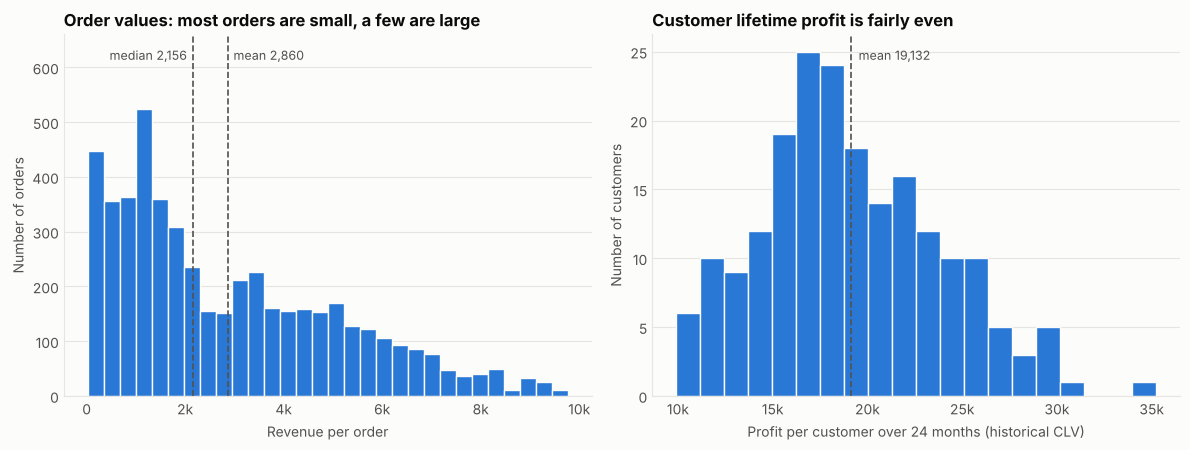

Top 20% of customers generate 26.5% of revenue
Customers who purchased in the last 60 days of data: 165 of 200


In [21]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6))
a1.hist(df.Revenue, bins=30, color=BLUE, edgecolor=SURF, linewidth=1)
a1.set_ylim(0, a1.get_ylim()[1] * 1.2)
for v, lab, y, side in [(aov, f"mean {aov:,.0f}", 0.93, 1), (aov_med, f"median {aov_med:,.0f}", 0.93, -1)]:
    a1.axvline(v, color=INK2, lw=1.2, ls="--")
    a1.text(v + side * 120, a1.get_ylim()[1] * y, lab, color=INK2, fontsize=9, ha="left" if side > 0 else "right")
a1.xaxis.set_major_formatter(MONEY); a1.set_xlabel("Revenue per order"); a1.set_ylabel("Number of orders")
a1.set_title("Order values: most orders are small, a few are large"); style(a1)

a2.hist(cust.Profit, bins=20, color=BLUE, edgecolor=SURF, linewidth=1)
mp = cust.Profit.mean(); a2.axvline(mp, color=INK2, lw=1.2, ls="--")
a2.text(mp + 400, a2.get_ylim()[1] * 0.93, f"mean {mp:,.0f}", color=INK2, fontsize=9)
a2.xaxis.set_major_formatter(MONEY); a2.set_xlabel("Profit per customer over 24 months (historical CLV)"); a2.set_ylabel("Number of customers")
a2.set_title("Customer lifetime profit is fairly even"); style(a2)
fig.tight_layout(); save(fig, "q5_aov_clv.png"); plt.show()

top20 = cust.Revenue.nlargest(int(len(cust) * 0.2)).sum() / cust.Revenue.sum()
print(f"Top 20% of customers generate {top20:.1%} of revenue")
print("Customers who purchased in the last 60 days of data:", (cust.Last >= df.Date.max() - pd.Timedelta(days=60)).sum(), "of", len(cust))

**Takeaway.**
- **AOV is 2,860** (median 2,156), with about 3 units per order. The mean is above the median because a minority of large orders (up to 9.8k) pull it up.
- **Historical CLV: each customer has generated about 71.5k in revenue and 19.1k in profit** over the two years (median profit 18.6k; range 9.9k–35.2k). That is roughly **9.6k profit per customer per year**, or about 28.7k over an assumed 3-year relationship.
- Customers are frequent buyers: ~25 orders each (≈12.5 per year), and **165 of 200 (83%) bought again within the last 60 days of the data**.
- **Value is not concentrated.** The top 20% of customers make up only 26.5% of revenue (not the 80/20 pattern many retailers see), so there are no "whale" customers to protect, and the business depends on the whole customer base.

---
## Q6. How do discounts affect revenue?
Discounts are 0%, 5%, 10% or 15%. I check three things: whether discounts **increase quantity sold**, what they **cost**, and what they do to **profit margin**.

In [22]:
d = df.groupby("Discount").agg(Orders=("TransactionID", "count"), AvgUnits=("Quantity", "mean"),
                               AvgListValue=("GrossSales", "mean"), AvgRevenue=("Revenue", "mean"),
                               Revenue=("Revenue", "sum"), DiscountCost=("DiscountAmount", "sum"), Profit=("Profit", "sum"))
d["Margin"] = d.Profit / d.Revenue
d.index = [f"{int(i * 100)}%" for i in d.index]
display(d)

p_qty = stats.f_oneway(*[g.Quantity for _, g in df.groupby("Discount")]).pvalue
print(f"Quantity per order vs discount level: ANOVA p = {p_qty:.2f}; correlation(discount, quantity) = {df.Discount.corr(df.Quantity):+.3f}")
print(f"Total discount given: {df.DiscountAmount.sum():,.0f} = {df.DiscountAmount.sum()/df.GrossSales.sum():.1%} of list-price sales")
no_disc_profit = (df.GrossSales - df.TotalCost).sum()
print(f"Profit if the same quantities had sold at full price: {no_disc_profit:,.0f} vs actual {df.Profit.sum():,.0f} ({no_disc_profit/df.Profit.sum()-1:+.1%})")

,Orders,AvgUnits,AvgListValue,AvgRevenue,Revenue,DiscountCost,Profit,Margin
0%,1243,3.00,"3,094.51","3,094.51","3,846,472.43",0.00,"1,237,899.91",0.32
5%,1250,2.98,"3,074.88","2,921.13","3,651,418.60","192,179.93","1,047,338.63",0.29
10%,1183,2.99,"3,155.98","2,840.39","3,360,176.42","373,352.94","833,282.57",0.25
15%,1324,2.99,"3,060.10","2,601.08","3,443,835.69","607,735.71","707,793.55",0.21


Quantity per order vs discount level: ANOVA p = 0.97; correlation(discount, quantity) = -0.002
Total discount given: 1,173,269 = 7.6% of list-price sales
Profit if the same quantities had sold at full price: 4,999,583 vs actual 3,826,315 (+30.7%)


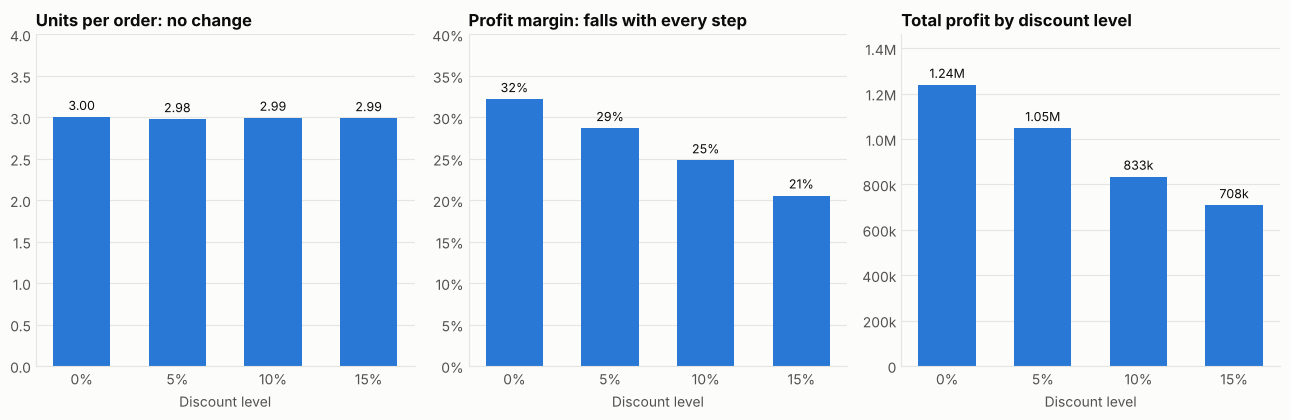

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
def panel(ax, vals, title, fmt, ylim):
    b = ax.bar(vals.index, vals.values, color=BLUE, width=0.6)
    ax.bar_label(b, labels=[fmt(v) for v in vals.values], padding=3, fontsize=9)
    ax.set_ylim(*ylim); ax.set_title(title); ax.set_xlabel("Discount level"); style(ax)
panel(axes[0], d.AvgUnits, "Units per order: no change", lambda v: f"{v:.2f}", (0, 4))
panel(axes[1], d.Margin, "Profit margin: falls with every step", lambda v: f"{v:.0%}", (0, 0.4))
axes[1].yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:.0%}"))
panel(axes[2], d.Profit, "Total profit by discount level", money2, (0, d.Profit.max() * 1.18))
axes[2].yaxis.set_major_formatter(MONEY)
fig.tight_layout(); save(fig, "q6_discount_effect.png"); plt.show()

**Takeaway.**
- **Discounts do not increase sales volume.** Customers buy about 3.0 units per order whether the discount is 0% or 15% (p = 0.97, correlation ≈ 0). The four discount groups are also similar in size (1,183–1,324 orders each).
- **Discounts are expensive.** They gave away **1.17M, or 7.6% of list-price sales**. Margin drops from **32% with no discount to 21% at 15%**, and profit from 1.24M to 0.71M, even though a similar number of orders sits in each group.
- If the same quantities had sold at full price, profit would have been about **5.0M instead of 3.83M (+31%)**. This assumes buying would not change without discounts, which is what the data suggests, since discounts did not change quantities.
- **Caveat:** this is observational data. The pattern shows no benefit from discounting, but only a controlled test (e.g., discounts in some stores only) would prove it.

---
## Correlation between numeric variables
A heatmap of the correlation matrix shows which numeric variables move together. Values run from −1 (move opposite) to +1 (move together), and 0 means no linear relationship.

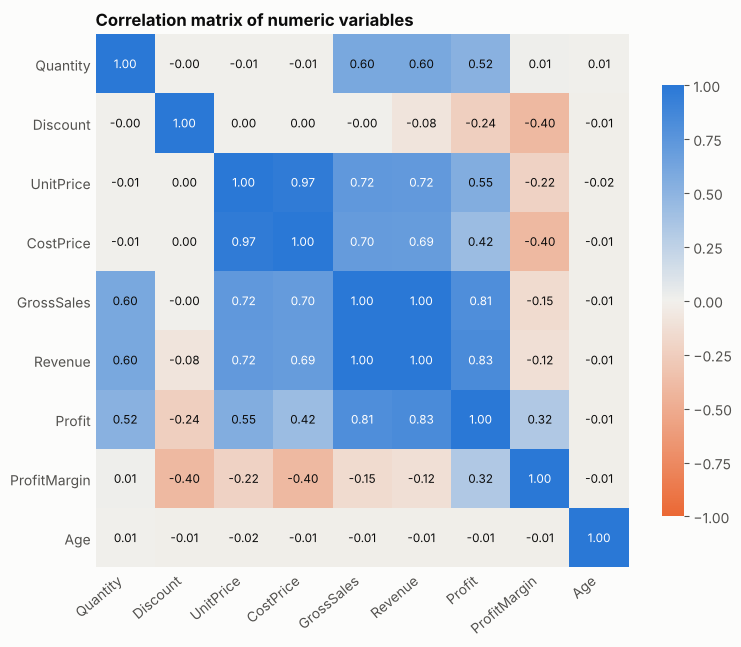

In [24]:
from matplotlib.colors import LinearSegmentedColormap
corr = df[num_cols].corr()
cmap = LinearSegmentedColormap.from_list("div", [ORANGE, "#f1f0ec", BLUE])   # two hues + neutral midpoint
fig, ax = plt.subplots(figsize=(8.6, 7))
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=40, ha="right"); ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5, color="white" if abs(v) > 0.6 else INK)
ax.grid(False); ax.tick_params(length=0)
for sp in ax.spines.values(): sp.set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.8); cb.outline.set_visible(False)
ax.set_title("Correlation matrix of numeric variables"); save(fig, "corr_heatmap.png"); plt.show()

**Observations.**
- **Revenue is driven by price and quantity.** Revenue correlates +0.72 with unit price and +0.60 with quantity, and profit follows revenue (+0.83).
- **Discount has no link to quantity** (0.00): giving a bigger discount does not make customers buy more, which confirms the Q6 finding. Its only visible effects are negative: on profit margin (−0.40) and profit (−0.24).
- **Higher-priced products earn a thinner margin** (unit price vs margin −0.22). This is explored in the next section.
- **Age has no relationship with anything** (all values about 0.00), in line with the Q4 demographics result.
- UnitPrice and CostPrice move almost together (0.97), as expected, so there is no sign of unusually priced products.
- Some pairs, such as Revenue with GrossSales, are related by construction, so a high value there says nothing new.

---
## Extra insight: the priciest products earn the most money but at the thinnest margin
To look beyond category and product, I split the 50 products into four **price tiers** (quartiles by unit price) and compare each tier's share of units sold, revenue and profit.

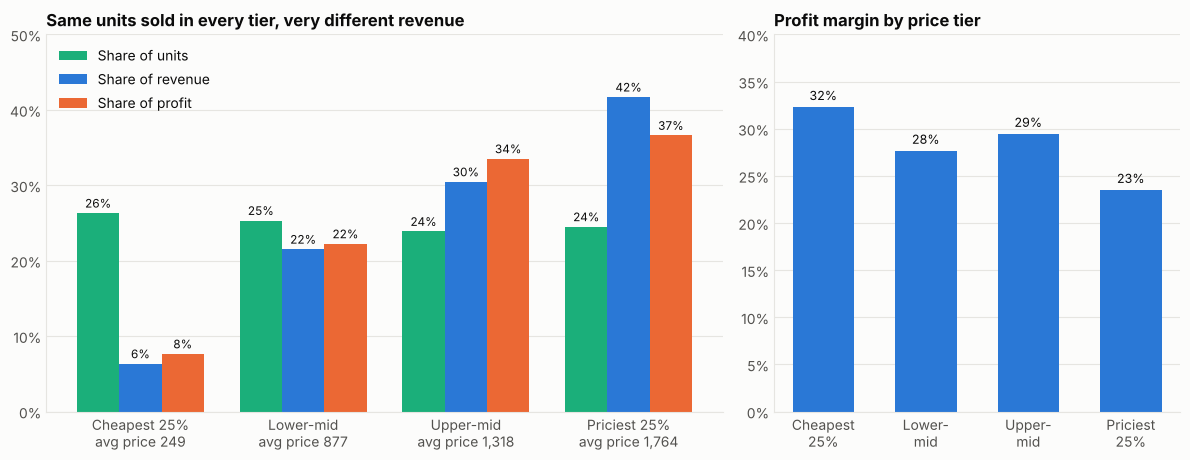

,Units,Revenue,Profit,AvgPrice,Margin
PriceTier,,,,,
Cheapest 25%,3932,"905,151.56","292,267.34",249.48,0.32
Lower-mid,3786,"3,077,615.96","850,760.55",876.78,0.28
Upper-mid,3569,"4,355,913.76","1,282,439.61","1,317.63",0.29
Priciest 25%,3662,"5,963,221.87","1,400,847.17","1,764.40",0.23


In [25]:
df["PriceTier"] = pd.qcut(df.UnitPrice, 4, labels=["Cheapest 25%", "Lower-mid", "Upper-mid", "Priciest 25%"])
tier = df.groupby("PriceTier", observed=True).agg(Units=("Quantity", "sum"), Revenue=("Revenue", "sum"), Profit=("Profit", "sum"),
                                                  AvgPrice=("UnitPrice", "mean"))
tier["Margin"] = tier.Profit / tier.Revenue
shares = tier[["Units", "Revenue", "Profit"]] / tier[["Units", "Revenue", "Profit"]].sum()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.7), gridspec_kw={"width_ratios": [5, 3]})
x = np.arange(len(tier)); w = 0.26
for k, (col, colr) in enumerate([("Units", AQUA), ("Revenue", BLUE), ("Profit", ORANGE)]):
    bars = a1.bar(x + (k - 1) * w, shares[col], w, color=colr, label=f"Share of {col.lower()}")
    a1.bar_label(bars, labels=[f"{v:.0%}" for v in shares[col]], padding=2, fontsize=8.5)
a1.set_xticks(x, [f"{t}\navg price {p:,.0f}" for t, p in zip(tier.index, tier.AvgPrice)])
a1.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:.0%}")); a1.set_ylim(0, 0.5)
a1.legend(loc="upper left"); a1.set_title("Same units sold in every tier, very different revenue"); style(a1)
b = a2.bar(range(len(tier)), tier.Margin, color=BLUE, width=0.6)
a2.bar_label(b, labels=[f"{v:.0%}" for v in tier.Margin], padding=3, fontsize=9)
a2.set_xticks(range(len(tier)), ["Cheapest\n25%", "Lower-\nmid", "Upper-\nmid", "Priciest\n25%"])
a2.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:.0%}")); a2.set_ylim(0, 0.4)
a2.set_title("Profit margin by price tier"); style(a2)
fig.tight_layout(); save(fig, "extra_price_tiers.png"); plt.show()
tier

**Observations.**
- **Customers buy the same number of units whatever the price:** each tier accounts for 24–26% of units sold. Demand is not discouraged by high prices.
- **So revenue is concentrated at the top:** the priciest quarter of products brings in **42% of revenue** and the cheapest quarter only **6%**.
- **But margin is thinnest at the top:** 23% for the priciest tier against 32% for the cheapest. The priciest tier is still the largest profit source (37% of profit), yet each unit of revenue there earns less.
- **Why this matters:** since volume does not fall as prices rise, there is room to test **modest price increases or lower supplier costs on the high-priced, low-margin products** (laptops, accessories, headphones) without relying on discounts.

---
## Conclusion: key insights and recommendations
| # | Insight | Evidence | Recommendation |
|---|---|---|---|
| 1 | **Revenue ≠ profit.** Electronics and Fashion earn similar revenue (44% each), but Fashion earns more profit; Groceries has the best margin (30%). | Q1 | Judge products by profit, not revenue. |
| 2 | **Some best sellers are weak earners.** *Book Television* (#1 revenue) has a 19% margin; *And Footwear* and *Set Dairy* earn 42%. Laptops (20%) and Accessories (23%) are low-margin. | Q1 | Promote high-margin lines; review pricing or supplier cost on laptops, cameras and accessories. |
| 3 | **Healthy, steady growth.** Like-for-like sales are +8.9% year on year with stable margins and little seasonality. | Q2 | Plan for steady demand; focus on growing the customer base rather than seasonal campaigns. |
| 4 | **Stores are evenly matched.** East leads only because it has two stores; the best store is just 6% ahead of the weakest. | Q3 | No store needs rescue; share best practice from New Michele (top store) with the others. |
| 5 | **Demographics don't change spend per customer** (age and gender differences are not significant). City is unique per customer. | Q4 | Don't over-invest in age or gender targeting; collect a broader location field (region/country) for geographic analysis. |
| 6 | **Customers buy often and are similarly valuable.** AOV 2,860; ~19.1k profit per customer over two years; ~25 orders each; 83% bought in the last 60 days; value is spread evenly. | Q5 | Protect the whole base through retention and loyalty, as there is no small "VIP" group to focus on. |
| 7 | **Discounts cost money but do not raise sales.** 1.17M given away; margin falls from 32% to 21% at 15%; units per order do not move. | Q6 | Cut or test removing discounts (e.g., in one store); profit could rise by up to ~30% if volume holds. |
| 8 | **Priciest products earn the most money at the thinnest margin.** The top price quartile gives 42% of revenue at 23% margin (cheapest quartile: 6% of revenue at 32%), while units sold are the same in every tier. | Extra insight | Test small price rises or cost reductions on high-priced, low-margin lines such as laptops, accessories and headphones. |

**Limitations.** (1) The data covers only 24 months (10 Sep 2023 – 9 Sep 2025), so 2023 and 2025 are partial years. (2) 19.9% of transactions occur before the customer's `JoinDate` (see Part 1), so `JoinDate` was not used for the analysis. (3) The data is observational, so findings show associations, not proven causes. (4) The dataset has no currency or customer region, which limits the geographic view.